**Navigation** : [Version Python](ML-09c-MatrixProfile-Multidim-Python.ipynb) | [ML-09b](ML-09b-TSAD-Benchmark-Flaws-Python.ipynb) | [Index](README.md)

# ML-09c — Matrix Profile multidimensionnel en C#

**Objectifs** : calculer des profils univariés et multidimensionnels, comparer condensations, ACP et carte de contrôle, puis mesurer l'effet des voisins multiples. **Prérequis** : distances, moyennes, C# et CPython. **Durée** : 90 minutes.

Le [carnet Python](ML-09c-MatrixProfile-Multidim-Python.ipynb) est la source pédagogique de ce port et présente le contexte bibliographique et l'annexe descriptive. Les expériences synthétiques ci-dessous ne reproduisent pas les évaluations externes et ne démontrent pas une performance générale.

Le code C# construit les signaux, classe les discords, compare les résultats et trace les figures. Python.NET appelle les implémentations réelles `stumpy.stump`, `stumpy.mstump` et `sklearn.decomposition.PCA` ; NumPy fournit les tirages du générateur de référence. Avant le lancement du noyau, configurez `PYTHONNET_PYDLL` vers la bibliothèque CPython et, si nécessaire, `PYTHONHOME` vers son installation et `PYTHONPATH` vers les paquets du même environnement (NumPy, STUMPY, Numba, scikit-learn).

In [1]:
// STUMPY et sklearn sont les moteurs scientifiques exacts, hébergés par Python.NET.
// Les appels acquièrent le GIL ; les données, les profils retournés et leurs rangs restent pilotés par C#.
#r "nuget: PythonNet, 3.1.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text.Json;
using System.Text;
using System.Globalization;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    var dll = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (string.IsNullOrWhiteSpace(dll))
        throw new InvalidOperationException("Définir PYTHONNET_PYDLL vers la bibliothèque CPython et installer STUMPY et scikit-learn.");
    Runtime.PythonDLL = dll;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}

string Infos()
{
    using (Py.GIL())
    {
        using var s = Py.CreateScope();
        s.Exec(@"import sys, numpy, stumpy, numba, sklearn
result = f'Python {sys.version.split()[0]} ; NumPy {numpy.__version__} ; STUMPY {stumpy.__version__} ; Numba {numba.__version__} ; scikit-learn {sklearn.__version__}'");
        return s.Get("result").As<string>();
    }
}

Console.WriteLine($".NET {Environment.Version} ; Python.NET {typeof(PythonEngine).Assembly.GetName().Version}");
Console.WriteLine(Infos());


The below script needs to be able to find the current output cell; this is an easy method to get it.

Installed Packages PythonNet, 3.1.0

.NET 10.0.15 ; Python.NET 3.1.0.0


Python 3.13.16 ; NumPy 2.5.2 ; STUMPY Please install this project with setup.py ; Numba 0.68.0 ; scikit-learn 1.6.1


## 1. Anomalie de cadence dans un capteur
Le profil d'une fenêtre mesure la distance z-normalisée à son plus proche voisin. STUMPY exclut par défaut une zone de rayon ceil(m/4) autour de la fenêtre : les fenêtres qui se chevauchent ne sont pas toutes exclues. Une méthode sans entraînement peut toujours être surajustée par choix répétés de fenêtre ou de seuil.

La série contient 1 600 points, période nominale 20, cadence multipliée par 1,9 entre 900 et 980 ; m=40. Les tirages NumPy sont identiques à ceux de la source pour permettre une comparaison directe.

In [2]:
// stump renvoie un profil par rang k et les indices de ses voisins.
// Le pont conserve des tableaux contigus float64 ; C# distingue ensuite profil univarié et profils par sous-espace.
record StumpResult(double[][] Distances, int[][] Voisins);
record MultiResult(double[][] Profils, int[][] Voisins);
string Bridge(string code, string input, int m = 0, int k = 0)
{
    using (Py.GIL())
    {
        using var scope = Py.CreateScope();
        using var arg = new PyString(input);
        using var pm = new PyInt(m);
        using var pk = new PyInt(k);
        scope.Set("input_json", arg);
        scope.Set("m", pm);
        scope.Set("k", pk);
        scope.Exec(code);
        return scope.Get("result_json").As<string>();
    }
}

double[] Normal(int seed, int count)
{
    string code = @"import json, numpy as np
cfg=json.loads(input_json)
rng=np.random.default_rng(cfg['seed'])
result_json=json.dumps(rng.normal(0,1,cfg['count']).tolist())";
    return JsonSerializer.Deserialize<double[]>(Bridge(code, JsonSerializer.Serialize(new { seed, count })));
}

StumpResult Stump(double[] data, int m, int k = 1)
{
    string code = @"import json, numpy as np, stumpy
x=np.ascontiguousarray(json.loads(input_json),dtype=np.float64)
r=stumpy.stump(x,m,k=k)
result_json=json.dumps({'p':r[:,:k].astype(float).T.tolist(),'i':r[:,k:2*k].astype(int).T.tolist()},allow_nan=False)";
    using var doc = JsonDocument.Parse(Bridge(code, JsonSerializer.Serialize(data), m, k));
    var root = doc.RootElement;
    return new StumpResult(JsonSerializer.Deserialize<double[][]>(root.GetProperty("p").GetRawText()), JsonSerializer.Deserialize<int[][]>(root.GetProperty("i").GetRawText()));
}

MultiResult Mstump(double[][] data, int m)
{
    string code = @"import json, numpy as np, stumpy
x=np.ascontiguousarray(json.loads(input_json),dtype=np.float64)
p,i=stumpy.mstump(x,m)
result_json=json.dumps({'p':p.tolist(),'i':i.tolist()},allow_nan=False)";
    using var doc = JsonDocument.Parse(Bridge(code, JsonSerializer.Serialize(data), m));
    var root = doc.RootElement;
    return new MultiResult(JsonSerializer.Deserialize<double[][]>(root.GetProperty("p").GetRawText()), JsonSerializer.Deserialize<int[][]>(root.GetProperty("i").GetRawText()));
}

double[] PcaScores(double[][] data)
{
    string code = @"import json, numpy as np
from sklearn.decomposition import PCA
x=np.asarray(json.loads(input_json),dtype=np.float64).T
model=PCA(n_components=2).fit(x)
res=((x-model.inverse_transform(model.transform(x)))**2).sum(axis=1)
result_json=json.dumps(res.tolist(),allow_nan=False)";
    return JsonSerializer.Deserialize<double[]>(Bridge(code, JsonSerializer.Serialize(data)));
}

double Quantile(double[] v, double q)
{
    var s = v.OrderBy(x => x).ToArray();
    double z = (s.Length - 1) * q;
    int a = (int)Math.Floor(z), b = (int)Math.Ceiling(z);
    return s[a] + (z - a) * (s[b] - s[a]);
}

double Moy(double[] x) => x.Average();
double Ecart(double[] x)
{
    double a = Moy(x);
    return Math.Sqrt(x.Average(v => (v - a) * (v - a)));
}

const int FS = 20, N1 = 1600, M1 = 40;
var bruit1 = Normal(2026, N1);
var serie1 = new double[N1];
double phase1 = 0;
for (int i = 0; i < N1; i++)
{
    phase1 += 2 * Math.PI * (i >= 900 && i < 980 ? 1.9 : 1) / FS;
    serie1[i] = 20 + 3 * Math.Sin(phase1) + 0.25 * bruit1[i];
}

var hors1 = serie1.Where((v, i) => i < 900 || i >= 980).ToArray();
var dans1 = serie1.Skip(900).Take(80).ToArray();
Console.WriteLine($"Série {N1} points ; anomalie [900,980) ; hors plage [{hors1.Min():F2},{hors1.Max():F2}], dedans [{dans1.Min():F2},{dans1.Max():F2}]");
Console.WriteLine($"Moyennes hors/dans {Moy(hors1):F3}/{Moy(dans1):F3} ; écarts-types {Ecart(hors1):F3}/{Ecart(dans1):F3}");


Série 1600 points ; anomalie [900,980) ; hors plage [16.37,23.67], dedans [16.72,23.36]


Moyennes hors/dans 19.996/20.071 ; écarts-types 2.136/2.180


Les plages se recouvrent : un score point par point ne modélise pas l'ordre temporel. Ce constat n'établit pas l'impossibilité de distinguer les fenêtres avec tout seuil ou toute autre donnée ; il faut mesurer le score choisi.

In [3]:
double mu1 = Moy(serie1), sd1 = Ecart(serie1);
var z1 = serie1.Select(v => Math.Abs((v - mu1) / sd1)).ToArray();
Console.WriteLine($"Carte |z|>3 : {z1.Count(v => v > 3)} alertes dont {z1.Skip(900).Take(80).Count(v => v > 3)} dans l'anomalie ; maximum intérieur {z1.Skip(900).Take(80).Max():F3}");
var mp1 = Stump(serie1, M1);
var profil1 = mp1.Distances[0];
int discord1 = Array.IndexOf(profil1, profil1.Max());
Console.WriteLine($"STUMPY stump : {profil1.Length} fenêtres, médiane {Quantile(profil1, 0.5):F3}, discord {discord1} distance {profil1[discord1]:F3}, voisin {mp1.Voisins[0][discord1]}, rapport {profil1[discord1] / Quantile(profil1, 0.5):F1}");


Carte |z|>3 : 0 alertes dont 0 dans l'anomalie ; maximum intérieur 1.573


STUMPY stump : 1561 fenêtres, médiane 0.799, discord 882 distance 6.429, voisin 1270, rapport 8.0


Sur cette réalisation, la carte à trois écarts-types et le profil ne donnent pas le même résultat. Une sous-séquence qui commence avant l'événement peut le chevaucher : on accepte par convention les débuts depuis 900−m dans l'évaluation.

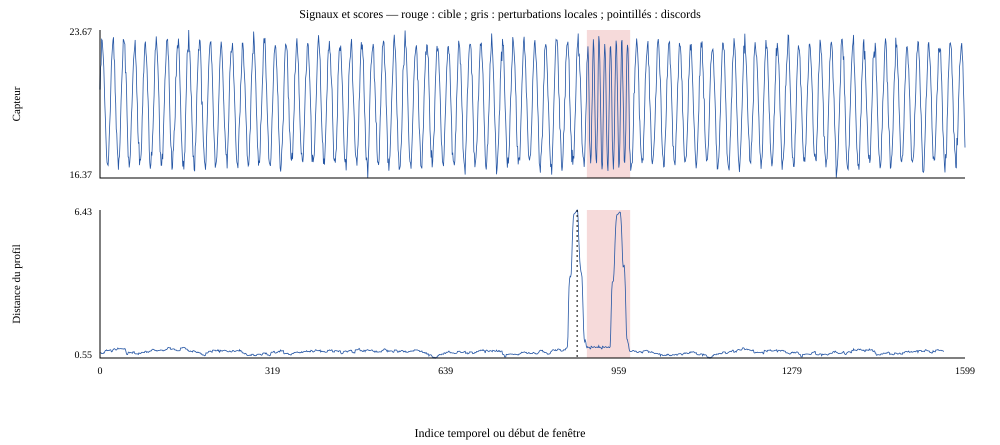

In [4]:
record Svg(string Content);
Formatter.Register<Svg>((v, w) => w.Write(v.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
// Le MIME image conserve les figures dans les lecteurs statiques de notebooks.
void AfficherSvg(Svg figure)
{
    display(figure, "image/svg+xml");
}

string F(double x) => x.ToString("0.##", CultureInfo.InvariantCulture);
string Esc(string s) => System.Security.SecurityElement.Escape(s);
string Panels(double[][][] panels, string[] labels, int length, int targetStart, int targetEnd, (int Start, int End)[] distractions = null, int[][] marks = null)
{
    int W = 1000, ph = 180, Left = 100, Right = 35, Top = 30, Bottom = 55, H = Top + panels.Length * ph + Bottom;
    var b = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='500' y='18' text-anchor='middle'>Signaux et scores — rouge : cible ; gris : perturbations locales ; pointillés : discords</text>");
    double X(int i) => Left + i / (double)(length - 1) * (W - Left - Right);
    string[] colors =
    {
        "#2455a4",
        "#c33b31",
        "#27946d"
    };
    for (int p = 0; p < panels.Length; p++)
    {
        double ytop = Top + p * ph, ybottom = ytop + ph - 32;
        var all = panels[p].SelectMany(a => a).ToArray();
        double ymin = all.Min(), ymax = all.Max();
        if (ymin == ymax)
            ymax = ymin + 1;
        double Y(double v) => ybottom - (v - ymin) / (ymax - ymin) * (ybottom - ytop);
        if (distractions != null)
            foreach (var d in distractions)
                b.Append($"<rect x='{F(X(d.Start))}' y='{F(ytop)}' width='{F(X(d.End) - X(d.Start))}' height='{F(ybottom - ytop)}' fill='#888' opacity='0.12'/>");
        b.Append($"<rect x='{F(X(targetStart))}' y='{F(ytop)}' width='{F(X(targetEnd) - X(targetStart))}' height='{F(ybottom - ytop)}' fill='#cc3333' opacity='0.18'/>");
        for (int j = 0; j < panels[p].Length; j++)
        {
            var pts = string.Join(" ", panels[p][j].Select((v, i) => $"{F(X(i))},{F(Y(v))}"));
            b.Append($"<polyline points='{pts}' fill='none' stroke='{colors[j % 3]}' stroke-width='0.8'/>");
        }

        if (marks != null && marks[p] != null)
            foreach (int i in marks[p])
                b.Append($"<line x1='{F(X(i))}' x2='{F(X(i))}' y1='{F(ytop)}' y2='{F(ybottom)}' stroke='black' stroke-dasharray='2 3'/>");
        b.Append($"<path d='M {Left} {F(ytop)} V {F(ybottom)} H {W - Right}' stroke='black' fill='none'/><text x='{Left - 8}' y='{F(ytop + 5)}' text-anchor='end' font-size='10'>{F(ymax)}</text><text x='{Left - 8}' y='{F(ybottom)}' text-anchor='end' font-size='10'>{F(ymin)}</text><text transform='translate(20,{F((ytop + ybottom) / 2)}) rotate(-90)' text-anchor='middle' font-size='11'>{Esc(labels[p])}</text>");
    }

    if (panels[0].Length == 3)
    {
        b.Append("<rect x='670' y='32' width='290' height='23' fill='white' opacity='0.9'/>");
        for (int k = 0; k < 3; k++)
            b.Append($"<text x='{680 + k * 90}' y='48' fill='{colors[k]}' font-size='10'>{new[] { "température", "pression", "vibration" }[k]}</text>");
    }

    for (int k = 0; k <= 5; k++)
    {
        int i = (length - 1) * k / 5;
        b.Append($"<text x='{F(X(i))}' y='{H - Bottom - 16}' text-anchor='middle' font-size='10'>{i}</text>");
    }

    b.Append($"<text x='500' y='{H - 8}' text-anchor='middle'>Indice temporel ou début de fenêtre</text></svg>");
    return b.ToString();
}

AfficherSvg(new Svg(Panels(new[] { new[] { serie1 }, new[] { profil1 } }, new[] { "Capteur", "Distance du profil" }, N1, 900, 980, marks: new[] { (int[])null, new[] { discord1 } })));


Le pic de profil est associé aux fenêtres dont la forme est peu commune ; le début de fenêtre peut précéder la région rouge. Les deux panneaux partagent l'axe des indices.

## 2. Trois capteurs : choix de condensation
Douze perturbations fortes touchent chacune un seul capteur ; un événement plus faible touche les trois ensemble. L'ACP de rang 2 et la carte |z| mesurent des points ; les profils comparent des fenêtres. Les données synthétiques ne prouvent pas une hiérarchie générale de méthodes.

In [5]:
// La cible commune modifie la cadence des trois capteurs, tandis que les hoquets sont locaux.
// Chaque phase est intégrée point par point ; le bruit NumPy conserve le tirage et la graine du source.
record Hoquet(int Capteur, int Debut, double Cadence);
const int N2 = 3000, M2 = 40;
const int AnomDebut = 1900, AnomFin = 1970;
string[] capteurs =
{
    "température",
    "pression",
    "vibration"
};
var hoquets = new[]
{
    new Hoquet(0, 200, 1.50),
    new Hoquet(1, 380, 1.63),
    new Hoquet(2, 560, 1.42),
    new Hoquet(0, 740, 1.71),
    new Hoquet(1, 920, 1.36),
    new Hoquet(2, 1100, 1.57),
    new Hoquet(0, 1280, 1.45),
    new Hoquet(1, 1460, 1.68),
    new Hoquet(2, 2200, 1.39),
    new Hoquet(0, 2380, 1.60),
    new Hoquet(1, 2560, 1.48),
    new Hoquet(2, 2740, 1.74)
};
double[][] Serie2(int graine)
{
    var bruit = Normal(graine, 3 * N2);
    var result = Enumerable.Range(0, 3).Select(_ => new double[N2]).ToArray();
    double[] phase =
    {
        0,
        0,
        0
    }, amplitude =
    {
        3,
        0.4,
        0.3
    }, niveau =
    {
        20,
        5,
        0.8
    }, sigma =
    {
        0.25,
        0.035,
        0.030
    };
    for (int i = 0; i < N2; i++)
        for (int k = 0; k < 3; k++)
        {
            double commun = i >= AnomDebut && i < AnomFin ? 1.14 : 1;
            var eventLocal = hoquets.FirstOrDefault(h => h.Capteur == k && i >= h.Debut && i < h.Debut + 70);
            double local = eventLocal == null ? 1 : eventLocal.Cadence;
            phase[k] += 2 * Math.PI * commun * local / FS;
            double angle = k == 0 ? phase[k] : k == 1 ? phase[k] + 0.6 : 2 * phase[k] + 1.1;
            result[k][i] = niveau[k] + amplitude[k] * Math.Sin(angle) + sigma[k] * bruit[k * N2 + i];
        }

    return result;
}

var T2 = Serie2(7);
Console.WriteLine($"Série : {T2.Length} capteurs × {T2[0].Length} points ; cible [{AnomDebut},{AnomFin}), cadence ×1.14 ; {hoquets.Length} hoquets locaux.");
for (int k = 0; k < 3; k++)
{
    var inside = T2[k].Skip(AnomDebut).Take(70).ToArray();
    var outside = T2[k].Where((v, i) => i < AnomDebut || i >= AnomFin).ToArray();
    Console.WriteLine($"{capteurs[k]} : hors moyenne {Moy(outside):F3}, écart {Ecart(outside):F3} ; dedans {Moy(inside):F3}, écart {Ecart(inside):F3}");
}


Série : 3 capteurs × 3000 points ; cible [1900,1970), cadence ×1.14 ; 12 hoquets locaux.


température : hors moyenne 19.997, écart 2.144 ; dedans 20.016, écart 2.143


pression : hors moyenne 5.000, écart 0.285 ; dedans 4.998, écart 0.284


vibration : hors moyenne 0.799, écart 0.214 ; dedans 0.807, écart 0.215


Les moyennes et écarts-types résument les marginales ; ils ne suffisent pas à établir leur égalité. On compare ensuite la reconstruction ACP et le maximum des scores |z| à leur propre fond.

In [6]:
// Le score SPC retient le plus grand écart centré-réduit parmi les capteurs.
// La comparaison pic/cen­tile distingue cible et fond pour les mêmes indices, sans confondre ce score avec le résidu PCA.
double[] ScoresSpc(double[][] T)
{
    var mu = T.Select(Moy).ToArray();
    var sd = T.Select(Ecart).ToArray();
    return Enumerable.Range(0, T[0].Length).Select(i => Enumerable.Range(0, T.Length).Max(k => Math.Abs((T[k][i] - mu[k]) / sd[k]))).ToArray();
}

var pcaScores = PcaScores(T2);
var spc = ScoresSpc(T2);
foreach (var(nom, score)in new[]
{
    ("ACP rang 2", pcaScores),
    ("Carte |z|", spc)
}

)
{
    var inside = score.Skip(AnomDebut).Take(70).ToArray();
    var outside = score.Where((v, i) => i < AnomDebut || i >= AnomFin).ToArray();
    Console.WriteLine($"{nom} : pic cible {inside.Max():F4}, 99e centile hors {Quantile(outside, 0.99):F4}, max hors {outside.Max():F4}");
}


ACP rang 2 : pic cible 0.1171, 99e centile hors 0.1191, max hors 0.1507


Carte |z| : pic cible 1.6326, 99e centile hors 1.6602, max hors 1.8052


Ces scores portent sur les points, non sur les séquences. Le pic intérieur est comparé au 99e centile du fond ; ce contraste est une mesure sur une réalisation, pas une preuve d'aveuglement universel.

In [7]:
// Après chaque maximum, une zone d’exclusion empêche de recompter ses voisins immédiats.
// Le rang teste le début des fenêtres recouvrant la cible ; un profil peut ne pas la placer dans les quinze premiers.
List<(int Index, double Valeur)> TopDiscords(double[] profil, int k = 15, int exclusion = M2)
{
    var p = (double[])profil.Clone();
    var pics = new List<(int, double)>();
    for (int z = 0; z < k; z++)
    {
        double v = p.Max();
        int i = Array.IndexOf(p, v);
        pics.Add((i, v));
        for (int j = Math.Max(0, i - exclusion); j < Math.Min(p.Length, i + exclusion); j++)
            p[j] = double.NegativeInfinity;
    }

    return pics;
}

int? Rang(double[] profil, int k = 15)
{
    var list = TopDiscords(profil, k);
    for (int j = 0; j < list.Count; j++)
        if (list[j].Index >= AnomDebut - M2 && list[j].Index < AnomFin)
            return j + 1;
    return null;
}

var profilsUni = Enumerable.Range(0, 3).Select(k => Stump(T2[k], M2).Distances[0]).ToArray();
Console.WriteLine("Profils univariés, rang dans les 15 premiers discords :");
for (int k = 0; k < 3; k++)
    Console.WriteLine($"{capteurs[k]} : rang {Rang(profilsUni[k])?.ToString() ?? "absent"} ; premiers indices {string.Join(",", TopDiscords(profilsUni[k], 3).Select(z => z.Index))}");


Profils univariés, rang dans les 15 premiers discords :


température : rang 6 ; premiers indices 722,176,1264


pression : rang 8 ; premiers indices 357,425,1446


vibration : rang 7 ; premiers indices 2729,2782,1140


Chaque capteur choisit son voisin indépendamment. Le classement filtre les pics voisins avec une zone d'exclusion de 40 indices pour éviter de compter plusieurs fois le même événement.

In [8]:
// Min, moyenne et max condensent des profils univariés déjà calculés séparément.
// mstump impose un voisin commun à ses sous-espaces : son rang K ne se confond pas avec une simple condensation.
int L = profilsUni[0].Length;
var condMin = Enumerable.Range(0, L).Select(i => profilsUni.Min(p => p[i])).ToArray();
var condMean = Enumerable.Range(0, L).Select(i => profilsUni.Average(p => p[i])).ToArray();
var condMax = Enumerable.Range(0, L).Select(i => profilsUni.Max(p => p[i])).ToArray();
var mps = Mstump(T2, M2);
foreach (var(nom, p)in new[]
{
    ("min", condMin),
    ("moyenne", condMean),
    ("max", condMax)
}

)
    Console.WriteLine($"Condensation {nom} : rang {Rang(p)?.ToString() ?? "absent"}");
for (int k = 1; k <= 3; k++)
    Console.WriteLine($"mSTAMP K={k} : rang {Rang(mps.Profils[k - 1])?.ToString() ?? "absent"}");
foreach (var(nom, i)in new[]
{
    ("anomalie", 1920),
    ("témoin", 1000)
}

)
    foreach (int k in new[]
    {
        1,
        3
    }

    )
        Console.WriteLine($"{nom} i={i}, K={k} : distance {mps.Profils[k - 1][i]:F4} ; voisin commun {mps.Voisins[k - 1][i]}");


Condensation min : rang 1


Condensation moyenne : rang 3


Condensation max : rang 10


mSTAMP K=1 : rang 1


mSTAMP K=2 : rang 1


mSTAMP K=3 : rang absent


anomalie i=1920, K=1 : distance 1.3161 ; voisin commun 1938


anomalie i=1920, K=3 : distance 1.6308 ; voisin commun 1938


témoin i=1000, K=1 : distance 0.7435 ; voisin commun 1260


témoin i=1000, K=3 : distance 1.1018 ; voisin commun 1020


`min`, moyenne et `max` combinent des profils déjà optimisés séparément. `mstump` choisit un voisin commun pour les dimensions retenues ; K indique combien de dimensions contribuent. K=1 peut ignorer un capteur perturbé si un autre trouve un voisin ; K=3 peut être sensible à un événement local. Aucun de ces effets ne garantit une détection pour toutes les données.

En notation D[i,j,k] pour la distance z-normalisée par dimension, le profil à K dimensions vaut min_j min_{S:|S|=K} moyenne_{k∈S} D[i,j,k]. Pour K=1, min des profils univariés et mSTAMP sont égaux : min_k min_j D = min_j min_k D. Le voisin commun introduit une distinction pour K>1, sans garantir l'unicité des indices en cas d'ex æquo.

### Cinq réalisations indépendantes
On répète le protocole pour les graines 7, 11, 42, 99 et 123 : trois profils univariés, mSTAMP, ACP et carte ponctuelle. Le rang est celui de la première fenêtre chevauchant la cible parmi les 15 premiers pics séparés.

In [9]:
// Chaque graine régénère les signaux puis évalue les onze méthodes sur les mêmes données.
// Le rang porte sur les premiers discords avec exclusion ; une absence est conservée comme valeur nullable.
Dictionary<string, int?> EvaluerTous(double[][] T)
{
    var uni = Enumerable.Range(0, 3).Select(k => Stump(T[k], M2).Distances[0]).ToArray();
    var mp = Mstump(T, M2);
    int n = uni[0].Length;
    var acp = PcaScores(T).Take(n).ToArray();
    var score = ScoresSpc(T).Take(n).ToArray();
    var min = Enumerable.Range(0, n).Select(i => uni.Min(p => p[i])).ToArray();
    var mean = Enumerable.Range(0, n).Select(i => uni.Average(p => p[i])).ToArray();
    var max = Enumerable.Range(0, n).Select(i => uni.Max(p => p[i])).ToArray();
    return new Dictionary<string, int?>
    {
        {
            "Carte M+3s",
            Rang(score)
        },
        {
            "ACP rang 2",
            Rang(acp)
        },
        {
            "MP température",
            Rang(uni[0])
        },
        {
            "MP pression",
            Rang(uni[1])
        },
        {
            "MP vibration",
            Rang(uni[2])
        },
        {
            "Condensation min",
            Rang(min)
        },
        {
            "Condensation moyenne",
            Rang(mean)
        },
        {
            "Condensation max",
            Rang(max)
        },
        {
            "mSTAMP K=1",
            Rang(mp.Profils[0])
        },
        {
            "mSTAMP K=2",
            Rang(mp.Profils[1])
        },
        {
            "mSTAMP K=3",
            Rang(mp.Profils[2])
        }
    };
}

int[] graines =
{
    7,
    11,
    42,
    99,
    123
};
var resultats = new Dictionary<string, List<int?>>();
foreach (int seed in graines)
{
    var r = EvaluerTous(Serie2(seed));
    foreach (var(nom, rang)in r)
    {
        if (!resultats.ContainsKey(nom))
            resultats[nom] = new List<int?>();
        resultats[nom].Add(rang);
    }
}

Console.WriteLine("Rang parmi les 15 premiers discords ; tiret = absent :");
Console.WriteLine("Détecteur | 7 11 42 99 123");
foreach (var(nom, rangs)in resultats)
    Console.WriteLine($"{nom, -24} | {string.Join(" ", rangs.Select(v => v?.ToString() ?? "-"))}");


Rang parmi les 15 premiers discords ; tiret = absent :


Détecteur | 7 11 42 99 123


Carte M+3s               | 4 11 9 5 -


ACP rang 2               | - - 14 10 -


MP température           | 6 8 8 7 6


MP pression              | 8 9 8 9 9


... (3 outputs left out)

Condensation max         | 10 10 11 9 11


mSTAMP K=1               | 1 1 1 1 1


mSTAMP K=2               | 1 1 1 1 1


mSTAMP K=3               | - - - - -


La répétition permet de voir si un résultat est stable sur ces cinq tirages. Un rang absent signifie seulement qu'il n'appartient pas au top 15 selon cette convention ; il ne démontre pas qu'un détecteur est universellement aveugle.

### Exercice 1 — Médiane et vote par dimension
Complétez une fonction de médiane et une fonction de vote : pour chaque capteur, le vote vaut 1 si son profil dépasse son propre quantile, puis on moyenne les votes. Comparez leurs rangs à min et moyenne sur les cinq graines. Les gardes utilisent deux tableaux non triviaux et deux quantiles.

In [10]:
bool VerifierCondensations(Func<double[][], double[]> mediane, Func<double[][], double, double[]> vote)
{
    if (mediane == null || vote == null)
        return false;
    var essais = new[]
    {
        (P: new[] { new[] { 1.0, 2, 30, 4 }, new[] { 4.0, 1, 2, 8 }, new[] { 7.0, 3, 1, 6 } }, Q: 0.75, A: new[] { 4.0, 2, 2, 6 }, B: new[] { 1 / 3.0, 0, 1 / 3.0, 1 / 3.0 }),
        (P: new[] { new[] { 8.0, 0, 4 }, new[] { 3.0, 9, 1 }, new[] { 2.0, 2, 7 } }, Q: 0.5, A: new[] { 3.0, 2, 4 }, B: new[] { 1 / 3.0, 1 / 3.0, 1 / 3.0 })
    };
    foreach (var z in essais)
    {
        var a = mediane(z.P);
        var b = vote(z.P, z.Q);
        int n = z.P[0].Length;
        if (a == null || b == null || a.Length != n || b.Length != n || a.Any(v => !double.IsFinite(v)) || b.Any(v => !double.IsFinite(v)))
            return false;
        for (int i = 0; i < n; i++)
            if (Math.Abs(a[i] - z.A[i]) > 1e-10 || Math.Abs(b[i] - z.B[i]) > 1e-10)
                return false;
    }

    return true;
}

Func<double[][], double[]> medianeEx = null; // TODO : médiane des dimensions pour chaque fenêtre
Func<double[][], double, double[]> voteEx = null; // TODO : fraction des dimensions au-dessus de leur quantile
Console.WriteLine(medianeEx == null || voteEx == null ? "Exercice 1 à compléter" : $"Condensations valides : {VerifierCondensations(medianeEx, voteEx)}");


Exercice 1 à compléter


### Figure de synthèse
Le premier panneau montre les trois signaux centrés-réduits ; les suivants montrent l'ACP, le profil de température et mSTAMP K=1. Les bandes grises sont les douze événements locaux, la bande rouge la cible et les pointillés les trois premiers discords.

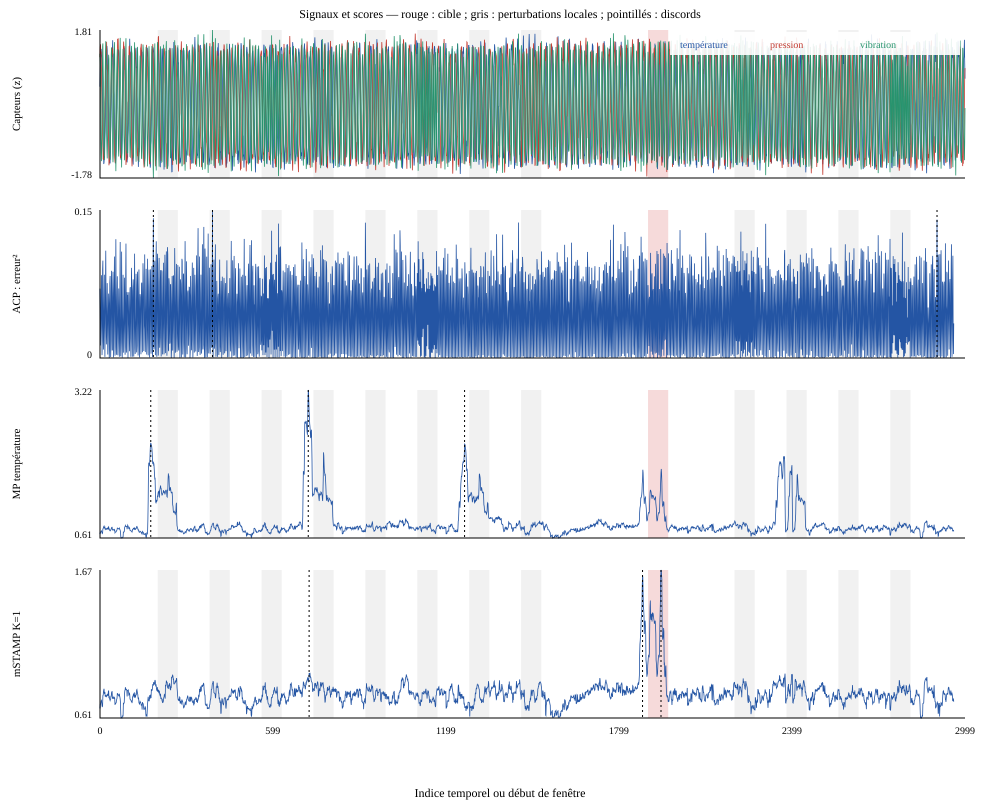

In [11]:
// Les trois capteurs sont standardisés seulement pour leur affichage sur une même échelle.
// Les panneaux de scores gardent les indices de début de fenêtre et les marques des discords avec exclusion.
var mpsFig = Mstump(T2, M2);
int nss = profilsUni[0].Length;
var normalises = T2.Select(row =>
{
    double avg = Moy(row), sd = Ecart(row);
    return row.Select(v => (v - avg) / sd).ToArray();
}).ToArray();
var pcaCourte = pcaScores.Take(nss).ToArray();
var panels = new[]
{
    normalises,
    new[]
    {
        pcaCourte
    },
    new[]
    {
        profilsUni[0]
    },
    new[]
    {
        mpsFig.Profils[0]
    }
};
var marques = new[]
{
    (int[])null,
    TopDiscords(pcaCourte, 3).Select(z => z.Index).ToArray(),
    TopDiscords(profilsUni[0], 3).Select(z => z.Index).ToArray(),
    TopDiscords(mpsFig.Profils[0], 3).Select(z => z.Index).ToArray()
};
var bandes = hoquets.Select(h => (h.Debut, h.Debut + 70)).ToArray();
AfficherSvg(new Svg(Panels(panels, new[] { "Capteurs (z)", "ACP : erreur²", "MP température", "mSTAMP K=1" }, N2, AnomDebut, AnomFin, bandes, marques)));


Les positions des pics sont à comparer aux bandes, plutôt qu'à interpréter sans tenir compte de la longueur de fenêtre. La synthèse reprend les mêmes données et recalcule mSTAMP pour la figure.

## 3. Anomalies répétées et k voisins
Deux occurrences de forme similaire peuvent devenir voisines. On construit une série de 1 600 points, une puis deux occurrences à 500 et 1 100, et on mesure les profils pour k=1,2,3 avec m=40. Le pic est comparé à deux fois le 99e centile du fond.

In [12]:
// Une deuxième occurrence peut devenir le voisin de la première et réduire sa distance de profil.
// Le test varie le rang de voisin k en conservant longueur, fenêtres et zone positive pour distinguer motif répété et discord.
const int N3 = 1600, M3 = 40, KMax = 3;
int[] debuts =
{
    500,
    1100
};
double[] Serie3(int occurrences, int seed = 5)
{
    var bruit = Normal(seed, N3);
    var x = new double[N3];
    double phase = 0;
    for (int i = 0; i < N3; i++)
    {
        double cadence = debuts.Take(occurrences).Any(d => i >= d && i < d + 70) ? 1 + 2.0 / 7 : 1;
        phase += 2 * Math.PI * cadence / FS;
        x[i] = 20 + 3 * Math.Sin(phase) + 0.25 * bruit[i];
    }

    return x;
}

for (int occurrences = 1; occurrences <= 2; occurrences++)
{
    var z = Stump(Serie3(occurrences), M3, KMax);
    for (int k = 1; k <= KMax; k++)
    {
        var p = z.Distances[k - 1];
        var mask = new bool[p.Length];
        foreach (int debut in debuts.Take(occurrences))
            for (int i = Math.Max(0, debut - M3); i < Math.Min(p.Length, debut + 70); i++)
                mask[i] = true;
        double pic = p.Where((v, i) => mask[i]).Max(), fond = Quantile(p.Where((v, i) => !mask[i]).ToArray(), 0.99);
        Console.WriteLine($"{occurrences} occurrence(s), k={k} : pic {pic:F3}, fond p99 {fond:F3}, pic>2×fond : {pic > 2 * fond}");
    }
}


1 occurrence(s), k=1 : pic 3.616, fond p99 0.911, pic>2×fond : True


1 occurrence(s), k=2 : pic 3.677, fond p99 0.932, pic>2×fond : True


1 occurrence(s), k=3 : pic 3.685, fond p99 0.953, pic>2×fond : True


2 occurrence(s), k=1 : pic 1.161, fond p99 0.913, pic>2×fond : False


2 occurrence(s), k=2 : pic 2.433, fond p99 0.939, pic>2×fond : True


2 occurrence(s), k=3 : pic 2.685, fond p99 0.954, pic>2×fond : True


Ces six mesures montrent l'effet du nombre d'occurrences et du rang du voisin dans ce jeu construit. La hausse de k change aussi le fond : il ne suffit pas de postuler qu'un k plus grand est toujours meilleur.

### Exercice 2 — Contraste et nombre de voisins
Implémentez le rapport pic sur les zones anormales / 99e centile du fond, en acceptant une marge avant chaque début. Le garde teste deux profils et plusieurs zones. Étendez ensuite les débuts à trois occurrences (multiples de FS), construisez les cas r=1, 2 et 3 et tracez leurs trois courbes de contraste pour k=1 à 6. Formulez une règle de choix de k et le coût de sa surestimation ; la zone d’exclusion laisse certains chevauchements, donc r occurrences ne garantissent pas exactement r−1 voisins proches.

In [13]:
bool VerifierContraste(Func<double[], int[], int, int, double?> candidat)
{
    if (candidat == null)
        return false;
    var essais = new[]
    {
        (P: Enumerable.Range(1, 20).Select(i => (double)i).ToArray(), D: new[] { 5, 14 }, L: 2, M: 1, Attendu: 0.8052340211373932),
        (P: Enumerable.Range(0, 30).Select(i => 1 + 3.0 * i / 29).ToArray(), D: new[] { 12 }, L: 3, M: 2, Attendu: 0.6158917418459403)
    };
    foreach (var z in essais)
    {
        var v = candidat(z.P, z.D, z.L, z.M);
        if (!v.HasValue || !double.IsFinite(v.Value) || Math.Abs(v.Value - z.Attendu) > 1e-10)
            return false;
    }

    return true;
}

Func<double[], int[], int, int, double?> contrasteEx = null; // TODO : calculer pic / p99 du fond
Console.WriteLine(contrasteEx == null ? "Exercice 2 à compléter" : $"Contraste valide : {VerifierContraste(contrasteEx)}");


Exercice 2 à compléter


## 4. Ouverture : profil et représentation apprise
Le [carnet Python](ML-09c-MatrixProfile-Multidim-Python.ipynb) présente une annexe historique sur l'utilisation du profil avec un auto-encodeur. Une piste générale est de comparer reconstruction et structure de voisinage dans une représentation latente ; aucune architecture externe n'est entraînée ou évaluée ici.

```mermaid
flowchart LR
 X[Série] --> E[Encodeur] --> Z[Représentation] --> D[Décodeur] --> R[Reconstruction]
 X --> P[Profil de fenêtres]
 P --> L[Comparaison de voisinage]
 Z --> L
```

Une telle combinaison impose de vérifier séparément ses hypothèses et ses résultats : l'absence de phase d'entraînement pour le profil ne rend pas le système complet insensible aux choix de validation.

### Exercice 3 — Anomalie subtile et verdict
Construisez une nouvelle anomalie par permutation des valeurs dans [1900,1970) pour préserver exactement les marginales de chaque capteur dans cette zone. Le garde vérifie les dimensions, les valeurs finies, les zones extérieures inchangées et l'ordre modifié. Comparez ensuite ACP, carte de contrôle et profil multidimensionnel sur plusieurs graines, et exposez les limites de votre protocole.

In [14]:
bool VerifierAnomalie(double[][] candidat)
{
    if (candidat == null || candidat.Length != 3 || candidat.Any(a => a == null || a.Length != N2 || a.Any(v => !double.IsFinite(v))))
        return false;
    bool change = false;
    for (int k = 0; k < 3; k++)
    {
        for (int i = 0; i < N2; i++)
        {
            if (i < AnomDebut || i >= AnomFin)
            {
                if (candidat[k][i] != T2[k][i])
                    return false;
            }
            else if (candidat[k][i] != T2[k][i])
                change = true;
        }

        var a = candidat[k].Skip(AnomDebut).Take(70).OrderBy(v => v).ToArray();
        var b = T2[k].Skip(AnomDebut).Take(70).OrderBy(v => v).ToArray();
        if (!a.SequenceEqual(b))
            return false;
    }

    return change;
}

double[][] anomalieEx = null; // TODO : permuter des valeurs dans la zone cible
Console.WriteLine(anomalieEx == null ? "Exercice 3 à compléter" : $"Anomalie valide : {VerifierAnomalie(anomalieEx)}");


Exercice 3 à compléter


## Exercices
Les trois exercices répartis ci-dessus portent sur la condensation, le contraste selon k et une anomalie qui conserve ses marginales.

## À retenir
| Choix | Effet à mesurer |
|---|---|
| Longueur et zone d'exclusion | Fenêtres comparées et voisinage autorisé |
| Condensation et K | Importance attribuée aux différentes dimensions |
| k voisins | Sensibilité aux répétitions et niveau du fond |

## Vérifiez votre compréhension
Pourquoi un discord peut-il commencer avant l'événement ?
<details><summary>Réponse</summary>La fenêtre qui commence avant l'événement peut le chevaucher.</details>

## Pour aller plus loin
Consultez le [carnet Python](ML-09c-MatrixProfile-Multidim-Python.ipynb) pour ses références et son annexe, et la [documentation STUMPY](https://stumpy.readme.io/).